In [1]:
'''redback shock cooling?'''

'redback shock cooling?'

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from redback import model_library
from redback.priors import get_priors
import redback
from lightcurvelynx.astro_utils.passbands import PassbandGroup
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.math_nodes.ra_dec_sampler import ObsTableRADECSampler
from lightcurvelynx.obstable.opsim import OpSim
from lightcurvelynx.simulate import simulate_lightcurves
from lightcurvelynx.survey_info import SurveyInfo
from lightcurvelynx.models.redback_models import RedbackWrapperModel
from lightcurvelynx.utils.extrapolate import ConstantPadding
from lightcurvelynx.utils.plotting import plot_lightcurves
from astropy import units as u
from lightcurvelynx import _LIGHTCURVELYNX_BASE_DATA_DIR

# Reset the matplotlib configuration
plt.rcParams.update(plt.rcParamsDefault)

# Set the seed so we don't get different results each time we run the notebook.
np.random.seed(42)

15:47 redback WARNING : No module named 'lalsimulation'
15:47 redback WARNING : lalsimulation is not installed. Some EOS based models will not work. Please use bilby eos or pass your own EOS generation class to the model
15:47 bilby INFO    : Running bilby version: 2.8.2
15:47 redback INFO    : Running redback version: 1.20.0


In [3]:
#there must be a way to not involve this but idk here we go

# Choose which filters to simulate.
filters = ["u", "g", "r", "i", "z", "y"]

# Load the OpSim data.
opsim_db = OpSim.from_url(
    "https://s3df.slac.stanford.edu/data/rubin/sim-data/sims_featureScheduler_runs5.3/baseline/baseline_v5.3.0_10yrs.db"
)
print(f"Loaded OpSim with {len(opsim_db)} rows.")

# Filter to only the rows that match the filters we want to simulate.
filter_mask = np.isin(opsim_db["filter"], filters)
opsim_db = opsim_db.filter_rows(filter_mask)

# Print the number of rows and time bounds after filtering.
t_min, t_max = opsim_db.time_bounds()
print(f"Filtered OpSim to {len(opsim_db)} rows and times [{t_min}, {t_max}]")

# Load the passband data for the griz filters only.
table_dir = _LIGHTCURVELYNX_BASE_DATA_DIR / "passbands" / "LSST"
passband_group = PassbandGroup.from_preset(
    preset="LSST",
    filters=filters,
    units="nm",
    trim_quantile=0.001,
    delta_wave=1,
    table_dir=table_dir,
)

survey_info = SurveyInfo(obstable=opsim_db, passbands=passband_group)

Loaded OpSim with 1844571 rows.
Filtered OpSim to 1844571 rows and times [61208.201382236985, 64860.44487408427]


In [4]:
#transient_models.shock_powered_models.shockcooling_morag

In [5]:
rb_model = model_library.all_models_dict["shockcooling_morag"]

In [6]:
rb_model_metadata = model_library.get_model_metadata(
    "shockcooling_morag",
    default=None,
)
print(rb_model_metadata)

None


In [7]:
rb_model?

Signature: rb_model(time, redshift, v_shock, m_env, f_rho_m, radius, kappa, **kwargs)
Docstring:
Lightcurve following the Morag, Sapir, & Waxman model

:param time: time in observer frame in days
:param redshift: redshift
:param v_shock: shock speed in km/s
:param m_env: envelope mass in solar masses
:param f_rho_m: f_rho * M (with M in solar masses). f_rho is typically, of order unity
:param radius: star/envelope radius in units of 10^13 cm
:param kappa: opacity in cm^2/g
:param kwargs: Additional parameters required by model
:param time_temp: Optional argument to set your desired time array (in source frame days) to evaluate the model on.
:param frequency: Required if output_format is 'flux_density'.
    frequency to calculate - Must be same length as time array or a single number).
:param bands: Required if output_format is 'magnitude' or 'flux'.
:param output_format: 'flux_density', 'magnitude', 'spectra', 'flux', 'sncosmo_source'
:param lambda_array: Optional argument to set your 

In [8]:
priors = redback.priors.get_priors(model=model_library.all_models_dict["shockcooling_morag"], constraint=True)

15:54 redback WARNING : No prior file found for model <function shockcooling_morag at 0x780075ec1940> in either priors or non_default_priors folders. Perhaps you also want to set up the prior for the base model? Or you may need to set up your prior explicitly.
15:54 redback INFO    : Returning Empty PriorDict.


In [64]:
#redback/priors/shock cooling/morag.prior

In [65]:
# priors

In [66]:
# !cat /Users/wickcedar/miniconda3/envs/oldpython/lib/python3.11/site-packages/redback/priors/shockcooling_morag.prior

In [67]:
# rb_model?

In [68]:
# NumpyRandomFunc?

In [14]:
parameters = {
    # "time" : 10, #is this an array?
    "redshift": NumpyRandomFunc("uniform", low=0.05, high=0.3),
    "v_shock" : 1e4, #NumpyRandomFunc("log_uniform", low=1e3, high=5e4),
    "m_env" : 1, #NumpyRandomFunc("log_uniform", low=1e-3, high=5),
    "f_rho_m" : NumpyRandomFunc("uniform", low=0.01, high=20),
    "radius" : 1,#NumpyRandomFunc("log_uniform", low=1e-2, high=10),
    "kappa" : NumpyRandomFunc("uniform", low=0.01, high=1),
    # "output_format" : 'sncosmo_source'
}

In [15]:
t0 = 64350.0

source = RedbackWrapperModel(
    rb_model,
    parameters=parameters,  # Set ALL the redback model parameters
    ra=0.0,  # Set other parameters
    dec=-10.0,
    t0=t0,
    phase_bounds=(1e-3, None),  # guess
    node_label="source",
    time_extrapolation=(ConstantPadding(0.0), ConstantPadding(0.0)),
)
# state = source.sample_parameters(num_samples=1)



In [57]:
from lightcurvelynx.simulate import compute_single_noise_free_lightcurve, compute_noise_free_lightcurves


In [69]:
# import lightcurvelynx
# help(lightcurvelynx.simulate)

In [59]:
graph_state = source.sample_parameters(num_samples=100)
passbands = PassbandGroup.from_svo("Palomar/ZTF")
lcs = compute_noise_free_lightcurves(source,
    graph_state,
    passbands, rest_frame_phase_min = -20, rest_frame_phase_max=1365, rest_frame_phase_step=.1)

In [72]:
# lcs

In [62]:
lcs['lightcurve'][0].keys()

Index(['times', 'rest_phase', 'g', 'g_fil', 'r', 'r_fil', 'i', 'i_fil'], dtype='str')

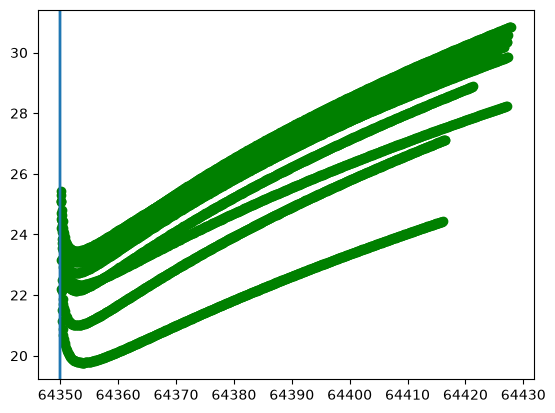

In [71]:
for i in range(10):
# plt.plot(lc['times'],lc['g'])
    lc = lcs['lightcurve'][i]
    plt.scatter((np.array(lc['times'])*u.day),(np.array(lc['g'])* u.nJy).to(u.ABmag, equivalencies=u.spectral()), c='green')
    plt.gca().invert_yaxis()
    plt.axvline(t0)
plt.show()

Alex TODO:
- [ ] Identify time of peak
- [ ] Define pre-peak and post-peak observations up to tmax=15
- [ ] Count pre- and post- peak points above a threshold f

In [44]:
def find_t_peak(lc, band):
    ipeak = np.argmax(lc[band])
    tpeak = lc['times'][ipeak]
    return ipeak, tpeak

In [45]:
find_t_peak(lc, 'g')

(np.int64(224), np.float64(64352.78119625082))

In [46]:
find_t_peak(lc, 'r')

(np.int64(239), np.float64(64354.51944390758))

In [73]:
def get_pre_peak(lc, band):
    ipeak, tpeak = find_t_peak(lc, band)
    tpre = lc['times'][:ipeak]
    fpre = lc[band][:ipeak]
    print(len(fpre)/len(lc[band]))
    return tpre, fpre

In [74]:
get_pre_peak(lc, 'g')

222

In [75]:
get_pre_peak(lc, 'r')

237

In [ ]:
# def get_post_peak(lc, band, fthresh=0):
    